# LogBERT V4 — run unifié HDFS + BGL avec améliorations

Un seul notebook, un seul run complet : HDFS et BGL partagent le même dépôt officiel (`a845e61`), le même protocole (train normal-only, sélection validation-only, test verrouillé) et les mêmes fonctions de scoring. Les datasets sont re-téléchargeables à tout moment (miroirs + reprise), donc aucune perte au reset.

Améliorations implémentées ici (cf. PLAN.md) : **S2** patch dataloader (`time_input` en `float32` direct, plus de `UserWarning`) ; **W3.1** mesure de la variance d'inférence ; **W3.2** scoring déterministe multi-passes (couverture 100 % garantie) ; **W1.1/W1.2** statistiques sessions courtes + routeur Fast-Path ; **I3** paramètres DRAIN dans l'évidence SLM ; **C1** tableau FinOps 2 colonnes ; validations renommées (interne normal-only vs calibration supervisée).

Configs retenues des ablation V2/V3 (non refaites ici) : HDFS `m=0.75` × 3 seeds, BGL `m=0.50` × 3 seeds.


## 1. Dépendances, dépôt officiel, patchs NumPy-2 (S2)

On garde le Torch de Kaggle. Patchs sans changement modèle : construction objet explicite (`sample.py`, `predict_log.py`) + `time_input`/`time_label` en `float32` direct dans `log_dataset.py` (S2 : supprime le `UserWarning` et accélère le transfert GPU). GPU requis.


In [1]:
# Garder le Torch de Kaggle ; fixer pandas compatible NumPy 2.x.
%pip install -q --force-reinstall --no-deps pandas==2.2.3
%pip install -q --no-deps regex==2023.12.25
print('Dépendances installées. En cas d erreur ABI, redémarrer le kernel puis relancer.')

import os, sys, json, ast, gc, random, shutil, subprocess, importlib.util, time as _time
from pathlib import Path
import numpy as np
if int(np.__version__.split(".")[0]) < 2:
    raise RuntimeError("NumPy 2.x requis.")
import pandas as pd
import torch
if not torch.cuda.is_available():
    raise RuntimeError("GPU non détecté : Settings > Accelerator > GPU.")
print("GPU :", torch.cuda.get_device_name(0))
for _name, _value in {"float": float, "int": int, "Inf": np.inf}.items():
    if not hasattr(np, _name):
        setattr(np, _name, _value)
if "torch._six" not in sys.modules:
    import types
    _torch_six = types.ModuleType("torch._six")
    _torch_six.string_classes = (str,)
    _torch_six.int_classes = (int,)
    sys.modules["torch._six"] = _torch_six
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score

REPO_URL = "https://github.com/HelenGuohx/LogBERT.git"
REPO_COMMIT = "a845e612e919a6930065b69a40098eaaac26e1a3"
WORK_DIR = Path(os.environ.get("LOGBERT_WORK_DIR", str(Path.cwd() / ".logbert_v4"))).expanduser().resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)
REPO_DIR = WORK_DIR / "LogBERT"
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
subprocess.run(["git", "-C", str(REPO_DIR), "checkout", REPO_COMMIT], check=True)
sys.path.insert(0, str(REPO_DIR))
print("Repo:", subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip())

# ---- Patchs dépôt officiel (idempotents) ----
import re as _re
_OBJECT_TMP = {"logkey_seq_pairs": "_tmp_logkey", "time_seq_pairs": "_tmp_time",
               "log_seqs": "_tmp_logseq", "tim_seqs": "_tmp_timseq"}
for _path, _vars in {
    REPO_DIR / "bert_pytorch" / "dataset" / "sample.py": ["logkey_seq_pairs", "time_seq_pairs"],
    REPO_DIR / "bert_pytorch" / "predict_log.py": ["log_seqs", "tim_seqs"],
}.items():
    _text = _path.read_text(encoding="utf-8")
    for _var in _vars:
        _tmp = _OBJECT_TMP[_var]
        if "np.empty(len(" + _tmp + "), dtype=object)" in _text:
            continue
        _m = _re.compile(r"^([ \t]*)" + _var + r" = np\.array\(" + _var + r"(?:, dtype=object)?\)[ \t]*$", _re.M).search(_text)
        if not _m:
            raise RuntimeError("Cible patch absente : " + _var)
        _ind = _m.group(1)
        _block = chr(10).join([_ind + _tmp + " = list(" + _var + ")",
                               _ind + _var + " = np.empty(len(" + _tmp + "), dtype=object)",
                               _ind + "for _i, _s in enumerate(" + _tmp + "):",
                               _ind + "    " + _var + "[_i] = _s",
                               _ind + "del " + _tmp])
        _text = _text[:_m.start()] + _block + _text[_m.end():]
    _path.write_text(_text, encoding="utf-8")
# S2 : tenseur temps direct en float32 (tue le UserWarning ligne ~130).
_ld = REPO_DIR / "bert_pytorch" / "dataset" / "log_dataset.py"
_ldt = _ld.read_text(encoding="utf-8")
for _old, _new in [
    ('output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)',
     'output["time_input"] = torch.tensor(np.asarray(output["time_input"], dtype=np.float32), dtype=torch.float)'),
    ('output["time_label"] = torch.tensor(output["time_label"], dtype=torch.float)',
     'output["time_label"] = torch.tensor(np.asarray(output["time_label"], dtype=np.float32), dtype=torch.float)'),
]:
    if _new not in _ldt and _old in _ldt:
        _ldt = _ldt.replace(_old, _new)
_ld.write_text(_ldt, encoding="utf-8")
print("Patchs appliqués (ragged explicite + time float32).")
for _mod in [m for m in list(sys.modules) if m == "bert_pytorch" or m.startswith("bert_pytorch.")]:
    del sys.modules[_mod]
from bert_pytorch import Trainer
from bert_pytorch.dataset.utils import seed_everything

# ---- Constantes protocole V4 (figées avant tout calcul) ----
BASE_SEED = 1234
random.seed(BASE_SEED); np.random.seed(BASE_SEED); torch.manual_seed(BASE_SEED)
torch.cuda.manual_seed_all(BASE_SEED)
HDFS_PRIOR = 10647 / (553366 + 10647)
BGL_PRIOR = 2630 / (10045 + 2630)
G_GRID = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]
R_GRID = np.arange(0.0, 0.801, 0.01)
HDFS_M, BGL_M = 0.75, 0.50
V4_SEEDS = [1234, 2026, 999]
RUN_HDFS, RUN_BGL = True, True
RUN_MULTIPASS, RUN_ROUTER, RUN_SLM = True, True, True
PAPER_HDFS = {"version": "Article HDFS", "Precision": .8702, "Recall": .7810, "F1": .8232}
PAPER_BGL = {"version": "Article BGL", "Precision": .8940, "Recall": .9232, "F1": .9083}
print("V4 prêt : HDFS m=%.2f | BGL m=%.2f | seeds %s" % (HDFS_M, BGL_M, V4_SEEDS))

def v4_download(urls, expected_size, expected_md5, target, label="archive"):
    import hashlib, urllib.request
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.exists() and target.stat().st_size == expected_size:
        print(label, "déjà présent.")
        return target
    ok, last = False, None
    import contextlib as _cl2
    @_cl2.contextmanager
    def _v4_fetch(url, req, attempt, have, target):
        if attempt == 1 and not have:
            with urllib.request.urlopen(url, timeout=120) as resp, target.open("wb") as out:
                yield resp, out
        else:
            resp = urllib.request.urlopen(req, timeout=300)
            mode = "ab" if (have and resp.status == 206) else "wb"
            with resp, target.open(mode) as out:
                yield resp, out
    for attempt in range(1, 5):
        for url in urls:
            try:
                print(f"Tentative {attempt} : {url[:70]}...")
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                have = target.stat().st_size if target.exists() else 0
                if have:
                    req.add_header("Range", f"bytes={have}-")
                with _v4_fetch(url, req, attempt, have, target) as (resp, out):
                    while True:
                        chunk = resp.read(4 * 1024 * 1024)
                        if not chunk:
                            break
                        out.write(chunk)
                if target.stat().st_size == expected_size:
                    ok = True
                    break
                print("Incomplet, nouvel essai...")
            except Exception as e:
                last = e
                print(f"Echec : {type(e).__name__} {str(e)[:120]}")
        if ok:
            break
        _time.sleep(30 * attempt)
    if not ok:
        raise RuntimeError(f"Echec {label} après reprises. Attacher via Add Input.") from last
    digest = hashlib.md5()
    with target.open("rb") as f:
        while True:
            chunk = f.read(8 * 1024 * 1024)
            if not chunk:
                break
            digest.update(chunk)
    if digest.hexdigest() != expected_md5:
        raise IOError("Checksum invalide.")
    print(label, "vérifié.")
    return target





     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 938.8 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 61.6 MB/s eta 0:00:0000:010:01
Note: you may need to restart the kernel to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.7/394.7 kB 2.0 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.
Dépendances installées. En cas d erreur ABI, redémarrer le kernel puis relancer.
GPU : Tesla T4


Cloning into '/kaggle/working/.logbert_v4/LogBERT'...
Note: switching to 'a845e612e919a6930065b69a40098eaaac26e1a3'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at a845e61 Create LICENSE


Repo: a845e612e919a6930065b69a40098eaaac26e1a3
Patchs appliqués (ragged explicite + time float32).
V4 prêt : HDFS m=0.75 | BGL m=0.50 | seeds [1234, 2026, 999]


## 2. Données HDFS (attacher d'abord, Zenodo sinon)

Ordre : `HDFS_LOG_PATH`/`HDFS_LABEL_PATH`, dossier `/kaggle/input` (Add Input : archive miroir HDFS_v1), sinon LogHub officiel avec reprises + MD5. Labels LogPai séparément (3 essais).


In [2]:
explicit_log = os.environ.get("HDFS_LOG_PATH")
explicit_labels = os.environ.get("HDFS_LABEL_PATH")
if explicit_log and explicit_labels:
    HDFS_LOG, LABEL_CSV = Path(explicit_log).expanduser().resolve(), Path(explicit_labels).expanduser().resolve()
else:
    roots = [Path("/kaggle/input"), Path("/content"), Path.cwd()]
    roots = list(dict.fromkeys(r.resolve() for r in roots if r.exists()))
    logs = [p for root in roots for p in root.rglob("*") if p.is_file() and p.name.lower() == "hdfs.log" and p.stat().st_size >= 100_000_000]
    labels = [p for root in roots for p in root.rglob("*") if p.is_file() and p.name.lower() == "anomaly_label.csv"]
    if logs and labels:
        HDFS_LOG, LABEL_CSV = logs[0], labels[0]
        print("HDFS attaché :", HDFS_LOG)
    else:
        dl = WORK_DIR / "dl_hdfs"
        arch = v4_download(
            ["https://zenodo.org/records/8196385/files/HDFS_v1.zip?download=1",
             "https://zenodo.org/api/records/8196385/files/HDFS_v1.zip/content"],
            186645559, "76a24b4d9a6164d543fb275f89773260", dl / "HDFS_v1.zip", "HDFS_v1.zip")
        import zipfile
        HDFS_LOG, LABEL_CSV = dl / "HDFS.log", dl / "anomaly_label.csv"
        if not HDFS_LOG.exists():
            with zipfile.ZipFile(arch) as z:
                member = next(n for n in z.namelist() if n.endswith("HDFS.log"))
                with z.open(member) as s, HDFS_LOG.open("wb") as d:
                    shutil.copyfileobj(s, d, length=8 * 1024 * 1024)
        if not LABEL_CSV.exists():
            import urllib.request
            for t in range(1, 4):
                try:
                    urllib.request.urlretrieve("https://raw.githubusercontent.com/logpai/loglizer/master/data/HDFS/anomaly_label.csv", LABEL_CSV)
                    break
                except Exception as e:
                    print("Labels :", e)
                    _time.sleep(15 * t)
label_df = pd.read_csv(LABEL_CSV)
label_df["BlockId"] = label_df.BlockId.astype(str)
print("HDFS.log %.2f Go ; labels %d" % (HDFS_LOG.stat().st_size / 1e9, len(label_df)), label_df.Label.value_counts().to_dict())
assert {"BlockId", "Label"}.issubset(label_df.columns) and label_df.BlockId.is_unique


Tentative 1 : https://zenodo.org/records/8196385/files/HDFS_v1.zip?download=1...
HDFS_v1.zip vérifié.
HDFS.log 1.58 Go ; labels 575061 {'Normal': 558223, 'Anomaly': 16838}


## 3. Données BGL (même mécanisme)

`BGL_LOG_PATH` ou `/kaggle/input`, sinon `BGL.zip` officiel (57 489 019 octets, MD5 vérifié). Labels intégrés au log (`-` = normal).


In [3]:
explicit_bgl = os.environ.get("BGL_LOG_PATH")
if explicit_bgl:
    BGL_LOG = Path(explicit_bgl).expanduser().resolve()
else:
    roots = [Path("/kaggle/input"), Path("/content"), Path.cwd()]
    roots = list(dict.fromkeys(r.resolve() for r in roots if r.exists()))
    found = [p for root in roots for p in root.rglob("*") if p.is_file() and p.name == "BGL.log" and p.stat().st_size >= 100_000_000]
    if found:
        BGL_LOG = found[0]
        print("BGL attaché :", BGL_LOG)
    else:
        dl = WORK_DIR / "dl_bgl"
        arch = v4_download(
            ["https://zenodo.org/records/8196385/files/BGL.zip?download=1",
             "https://zenodo.org/api/records/8196385/files/BGL.zip/content"],
            57489019, "4452953c470f2d95fcb32d5f6e733f7a", dl / "BGL.zip", "BGL.zip")
        import zipfile
        BGL_LOG = dl / "BGL.log"
        if not BGL_LOG.exists():
            with zipfile.ZipFile(arch) as z:
                member = next(n for n in z.namelist() if n.endswith("BGL.log"))
                with z.open(member) as s, BGL_LOG.open("wb") as d:
                    shutil.copyfileobj(s, d, length=8 * 1024 * 1024)
print("BGL.log %.2f Go" % (BGL_LOG.stat().st_size / 1e9))


Tentative 1 : https://zenodo.org/records/8196385/files/BGL.zip?download=1...
BGL.zip vérifié.
BGL.log 0.74 Go


## 4. Parsing Drain officiel HDFS + sessionnisation

`parser` (Drain depth=5, st=0.5), `mapping`, `hdfs_sampling` : inchangé V2.


In [4]:
REPO_HDFS = REPO_DIR / "HDFS"
OUTPUT_HDFS = REPO_DIR / "output" / "hdfs"
OUTPUT_HDFS.mkdir(parents=True, exist_ok=True)
(OUTPUT_HDFS / "bert").mkdir(parents=True, exist_ok=True)
DATA_HDFS = Path.home() / ".dataset" / "hdfs"
DATA_HDFS.mkdir(parents=True, exist_ok=True)
for source, target in [(HDFS_LOG, DATA_HDFS / "HDFS.log"), (LABEL_CSV, DATA_HDFS / "anomaly_label.csv")]:
    if target.exists() or target.is_symlink():
        target.unlink()
    target.symlink_to(source)
spec_h = importlib.util.spec_from_file_location("hdfs_data_process_v4", REPO_HDFS / "data_process.py")
dp_hdfs = importlib.util.module_from_spec(spec_h)
spec_h.loader.exec_module(dp_hdfs)
old_cwd = Path.cwd()
os.chdir(REPO_HDFS)
try:
    dp_hdfs.parser(str(DATA_HDFS) + "/", "../output/hdfs/", "HDFS.log",
                   "<Date> <Time> <Pid> <Level> <Component>: <Content>", "drain")
    dp_hdfs.mapping()
    dp_hdfs.hdfs_sampling("../output/hdfs/HDFS.log_structured.csv")
finally:
    os.chdir(old_cwd)
STRUCTURED_HDFS = OUTPUT_HDFS / "HDFS.log_structured.csv"
SEQUENCE_HDFS = OUTPUT_HDFS / "hdfs_sequence.csv"
assert STRUCTURED_HDFS.exists() and SEQUENCE_HDFS.exists()
print("Parsing HDFS OK :", list(pd.read_csv(STRUCTURED_HDFS, nrows=5).columns))


Parsing file: /root/.dataset/hdfs/HDFS.log


/kaggle/working/.logbert_v4/LogBERT/HDFS/data_process.py:35: SyntaxWarning: invalid escape sequence '\w'
  "(/[-\w]+)+", #replace file path with *
/kaggle/working/.logbert_v4/LogBERT/HDFS/data_process.py:36: SyntaxWarning: invalid escape sequence '\d'
  "(?<=blk_)[-\d]+" #replace block_id with *
/kaggle/working/.logbert_v4/LogBERT/logparser/Spell.py:318: SyntaxWarning: invalid escape sequence '\s'
  splitter = re.sub(' +', '\\\s+', splitters[k]) #re.sub(' +', '\s+', splitters[k])
/kaggle/working/.logbert_v4/LogBERT/logparser/Spell.py:333: SyntaxWarning: invalid escape sequence '\<'
  template_regex = "^" + template_regex.replace("\<\*\>", "(.*?)") + "$"
/kaggle/working/.logbert_v4/LogBERT/logparser/Drain.py:327: SyntaxWarning: invalid escape sequence '\s'
  splitter = re.sub(' +', '\\\s+', splitters[k])
/kaggle/working/.logbert_v4/LogBERT/logparser/Drain.py:341: SyntaxWarning: invalid escape sequence '\<'
  template_regex = "^" + template_regex.replace("\<\*\>", "(.*?)") + "$"


Total size after encoding is 11175629 11175629
Parsing done. [Time taken: 0:13:44.550269]
{'9b7aa7a3': 1, '2f313c72': 2, '2e1cf0aa': 3, '797b9c47': 4, 'b0023896': 5, 'bb837bbd': 6, '81358cb3': 7, '6caae5bd': 8, 'be6f070c': 9, 'd23206c6': 10, 'fa05ffa7': 11, '53c00e5f': 12, '0d168c98': 13, 'd7507d1e': 14, 'cf9b33dc': 15, 'd6115493': 16, '46f6e99a': 17, 'b46e298a': 18, 'fac2c191': 19, '4ed2a0c0': 20, '5e47c5c3': 21, '1995da3b': 22, '1d48c538': 23, 'b3ef6470': 24, 'ceedf750': 25, 'caed8b80': 26, '6f83a284': 27, '5832ad42': 28, 'c859931b': 29, '5ac8245b': 30, '190eb501': 31, 'f8ba9329': 32, '47b367ea': 33, '1ff93be5': 34, '72988c9b': 35, '78ad37b3': 36, '60600882': 37, 'ffa3fe68': 38, 'b55f27b2': 39, '9111794a': 40, 'a26fadbc': 41, 'f52097f4': 42, 'ebe1d2fb': 43, '0d527039': 44, '17ee882d': 45, 'fb314c6d': 46, '0555f7e9': 47}
Loading ../output/hdfs/HDFS.log_structured.csv


11175629it [08:07, 22936.32it/s]


hdfs sampling done
Parsing HDFS OK : ['LineId', 'Date', 'Time', 'Pid', 'Level', 'Component', 'Content', 'EventId', 'EventTemplate']


## 5. Parsing Drain officiel BGL + fenêtres 5 min

`parse_log` (Drain depth=3, st=0.3) puis réplique exacte du `__main__` officiel : labels, `sliding_window` 300 s / pas 60 s via `logdeep`.


In [5]:
REPO_BGL = REPO_DIR / "BGL"
OUTPUT_BGL = REPO_DIR / "output" / "bgl"
OUTPUT_BGL.mkdir(parents=True, exist_ok=True)
(OUTPUT_BGL / "bert").mkdir(parents=True, exist_ok=True)
DATA_BGL = Path.home() / ".dataset" / "bgl"
DATA_BGL.mkdir(parents=True, exist_ok=True)
target = DATA_BGL / "BGL.log"
if target.exists() or target.is_symlink():
    target.unlink()
target.symlink_to(BGL_LOG)
spec_b = importlib.util.spec_from_file_location("bgl_data_process_v4", REPO_BGL / "data_process.py")
dp_bgl = importlib.util.module_from_spec(spec_b)
spec_b.loader.exec_module(dp_bgl)
from logdeep.dataset.session import sliding_window
dp_bgl.parse_log(str(DATA_BGL) + "/", str(OUTPUT_BGL) + "/", "BGL.log", "drain")
STRUCTURED_BGL = OUTPUT_BGL / "BGL.log_structured.csv"
assert STRUCTURED_BGL.exists()
df_bgl = pd.read_csv(STRUCTURED_BGL)
df_bgl["datetime"] = pd.to_datetime(df_bgl["Time"], format="%Y-%m-%d-%H.%M.%S.%f")
df_bgl["Label"] = df_bgl["Label"].apply(lambda x: int(x != "-"))
df_bgl["timestamp"] = df_bgl["datetime"].values.astype(np.int64) // 10 ** 9
df_bgl["deltaT"] = (df_bgl["datetime"].diff() / np.timedelta64(1, "s")).fillna(0)
windows_bgl = sliding_window(df_bgl[["timestamp", "Label", "EventId", "deltaT"]],
                             para={"window_size": 5 * 60, "step_size": 1 * 60})
print("Fenêtres BGL :", len(windows_bgl), "| clés brutes :", df_bgl.EventId.nunique())


Parsing file: /root/.dataset/bgl/BGL.log
Total size after encoding is 4713493 4747963
Parsing done. [Time taken: 0:32:12.664555]
there are 37315 instances (sliding windows) in this dataset

Fenêtres BGL : 37315 | clés brutes : 1000


## 6. Splits identiques V2/V3 + fichiers courts + paramètres (W1.1, I3)

Splits figés : HDFS shuffle seed 20 / train 4 855, BGL shuffle seed 12 / ratio 0.4, validation 10 %/20 %, `min_len=10` pour LogBERT. **Nouveau** : les sessions `L<10` sont conservées dans des fichiers `short_*` labellisés (mesure de l'angle mort W1.1 + Fast-Path W1.2), et les `ParameterList` DRAIN (si présentes) sont persistées en sidecar JSON pour l'évidence SLM (I3). Validation interne normal-only du Trainer vs calibration supervisée : voir C2 dans le rapport.


In [6]:
NL = chr(10)
def _write_seq(frame, col, path):
    with path.open("w", encoding="utf-8") as stream:
        for events in frame[col]:
            stream.write(" ".join(map(str, events)) + NL)
def _file_lines(path):
    with open(path, encoding="utf-8") as f:
        return sum(1 for _ in f)

# ---------- HDFS ----------
seq_df = pd.read_csv(SEQUENCE_HDFS, dtype={"BlockId": str})
seq_df["events"] = seq_df.EventSequence.map(ast.literal_eval)
seq_df["label"] = seq_df.BlockId.map(dict(zip(label_df.BlockId, label_df.Label)))
seq_df = seq_df.dropna(subset=["label"]).reset_index(drop=True)
seq_df["y"] = (seq_df.label == "Anomaly").astype(int)
n_all = seq_df[seq_df.y == 0].sample(frac=1, random_state=20).reset_index(drop=True)
a_all = seq_df[seq_df.y == 1].sample(frac=1, random_state=20).reset_index(drop=True)
h_train = n_all.iloc[:4855].copy()
h_rem = n_all.iloc[4855:].reset_index(drop=True)
h_vn, h_tn = h_rem.iloc[:int(len(h_rem) * .10)].copy(), h_rem.iloc[int(len(h_rem) * .10):].copy()
h_va, h_ta = a_all.iloc[:int(len(a_all) * .20)].copy(), a_all.iloc[int(len(a_all) * .20):].copy()
H_PARTS = {"train": h_train, "val_normal": h_vn, "val_abnormal": h_va, "test_normal": h_tn, "test_abnormal": h_ta}
H_SHORT = {"short_normal": n_all[n_all.events.map(len) < 10], "short_abnormal": a_all[a_all.events.map(len) < 10]}
for name, fr in list(H_PARTS.items()) + list(H_SHORT.items()):
    fr = fr[fr.events.map(len) >= 10] if name not in H_SHORT else fr
    H_PARTS[name] = fr.reset_index(drop=True) if name in H_PARTS else fr
    _write_seq(fr, "events", OUTPUT_HDFS / name)
HDFS_COUNTS = {n: _file_lines(OUTPUT_HDFS / n) for n in list(H_PARTS) + list(H_SHORT)}
print("HDFS LogBERT :", {k: HDFS_COUNTS[k] for k in H_PARTS})
print("HDFS courts L<10 :", {k: HDFS_COUNTS[k] for k in H_SHORT})

# ---------- BGL ----------
b_n = windows_bgl[windows_bgl.Label == 0].sample(frac=1, random_state=12).reset_index(drop=True)
b_a = windows_bgl[windows_bgl.Label == 1].reset_index(drop=True)
b_train = b_n.iloc[:int(len(b_n) * 0.4)].reset_index(drop=True)
b_rem = b_n.iloc[int(len(b_n) * 0.4):].reset_index(drop=True)
b_vn, b_tn = b_rem.iloc[:int(len(b_rem) * .10)].copy(), b_rem.iloc[int(len(b_rem) * .10):].copy()
b_va, b_ta = b_a.iloc[:int(len(b_a) * .20)].copy(), b_a.iloc[int(len(b_a) * .20):].copy()
B_PARTS = {"train": b_train, "val_normal": b_vn, "val_abnormal": b_va, "test_normal": b_tn, "test_abnormal": b_ta}
B_SHORT = {"short_normal": b_n[b_n.EventId.map(len) < 10], "short_abnormal": b_a[b_a.EventId.map(len) < 10]}
for name, fr in list(B_PARTS.items()) + list(B_SHORT.items()):
    fr = fr[fr.EventId.map(len) >= 10] if name not in B_SHORT else fr
    B_PARTS[name] = fr.reset_index(drop=True) if name in B_PARTS else fr
    _write_seq(fr, "EventId", OUTPUT_BGL / name)
BGL_COUNTS = {n: _file_lines(OUTPUT_BGL / n) for n in list(B_PARTS) + list(B_SHORT)}
print("BGL LogBERT :", {k: BGL_COUNTS[k] for k in B_PARTS})
print("BGL courts L<10 :", {k: BGL_COUNTS[k] for k in B_SHORT})

# ---------- W1.1 : angle mort ----------
for tag, counts, short_n, short_a in [("HDFS", HDFS_COUNTS, "short_normal", "short_abnormal"),
                                      ("BGL", BGL_COUNTS, "short_normal", "short_abnormal")]:
    print(tag, "sessions courtes écartées de LogBERT :", counts[short_n], "normales /", counts[short_a], "anomalies")
(WORK_DIR / "v4_splits.json").write_text(json.dumps({"hdfs": HDFS_COUNTS, "bgl": BGL_COUNTS, "commit": REPO_COMMIT}, indent=2))
print("Splits sauvés.")


HDFS LogBERT : {'train': 4855, 'val_normal': 55336, 'val_abnormal': 2139, 'test_normal': 498032, 'test_abnormal': 8508, 'short_normal': 0, 'short_abnormal': 6191}
HDFS courts L<10 : {'short_normal': 0, 'short_abnormal': 6191}
BGL LogBERT : {'train': 6681, 'val_normal': 1010, 'val_abnormal': 535, 'test_normal': 9053, 'test_abnormal': 2091, 'short_normal': 17553, 'short_abnormal': 392}
BGL courts L<10 : {'short_normal': 17553, 'short_abnormal': 392}
HDFS sessions courtes écartées de LogBERT : 0 normales / 6191 anomalies
BGL sessions courtes écartées de LogBERT : 17553 normales / 392 anomalies
Splits sauvés.


## 7. Entraînements V4 (configs V2/V3, 3 seeds chacun)

HDFS `m=0.75` et BGL `m=0.50` (ablations déjà acquises, non refaites), seeds 1234/2026/999, splits figés. Reprise sur checkpoint. Courbes MLKP+VHM par dataset.


device cuda
features logkey:True time: False

mask ratio 0.65
arguments Namespace(vocab_size=None, encoding='utf-8', min_freq=1, mode='vocab')
Building Vocab
VOCAB SIZE: 20
save vocab in ../output/hdfs/vocab.pkl


100%|██████████| 4855/4855 [00:00<00:00, 228342.39it/s]


device cuda
features logkey:True time: False
mask ratio 0.5
arguments Namespace(vocab_size=None, encoding='utf-8', min_freq=1, mode='vocab')
Building Vocab


100%|██████████| 6681/6681 [00:01<00:00, 3435.25it/s]


vocab_size 185
Vocabs train-only : HDFS 20 | BGL 185
device cuda
features logkey:True time: False

mask ratio 0.65
device cuda
features logkey:True time: False
mask ratio 0.5
=== V4 hdfs seed=1234 m=0.75 ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v4/LogBERT/output/hdfs/vocab.pkl
vocab Size:  20

Loading Train Dataset
before filtering short session
train size  4370
valid size  485


...

Epoch: 48 | phase: train, loss=0.3111433142467457
logkey loss: 0.30289090797305107, hyper loss: 0.08252406848923248

Epoch: 48 | phase: valid, loss=0.39654146134853363
logkey loss: 0.38842912912368777, hyper loss: 0.08112339079380035

Log saved


start calculate center


100%|██████████| 15/15 [00:00<00:00, 73.02it/s]


Epoch: 49 | phase: train, loss=0.30797818456502524
logkey loss: 0.2999292464707704, hyper loss: 0.08048939463846824

Epoch: 49 | phase: valid, loss=0.38457240064938863
logkey loss: 0.3770682603120804, hyper loss: 0.07504143665234247

Log saved


start calculate center


100%|██████████| 15/15 [00:00<00:00, 74.43it/s]


Epoch: 50 | phase: train, loss=0.29817251017426744
logkey loss: 0.29056301658206124, hyper loss: 0.07609493778470684

Epoch: 50 | phase: valid, loss=0.40578665137290953
logkey loss: 0.3984264115492503, hyper loss: 0.07360234210888544

Log saved
Early stopping


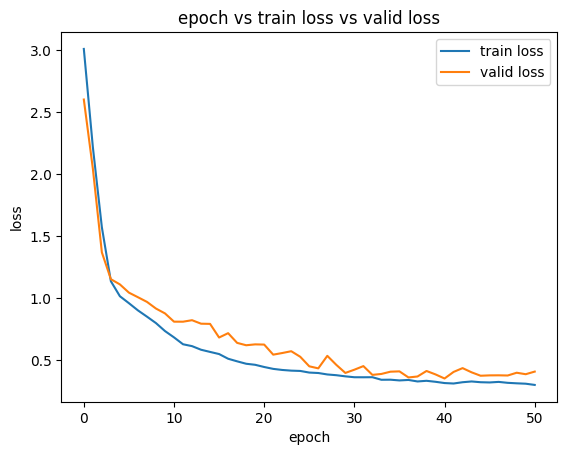

plot done
=== V4 hdfs seed=2026 m=0.75 ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v4/LogBERT/output/hdfs/vocab.pkl
vocab Size:  20

Loading Train Dataset
before filtering short session
train size  4370
valid size  485


100%|██████████| 4855/4855 [00:00<00:00, 84615.99it/s]

Num of train seqs 4370
Num of valid seqs 485

Loading valid Dataset
Creating Dataloader


Building BERT model
Creating BERT Trainer
Total Parameters: 2120213
Training Start


start calculate center


100%|██████████| 15/15 [00:00<00:00, 71.44it/s]


...

Epoch: 39 | phase: train, loss=0.3286566333297421
logkey loss: 0.3183837124310872, hyper loss: 0.10272922558600411

Epoch: 39 | phase: valid, loss=0.42128763993581136
logkey loss: 0.4115499764680862, hyper loss: 0.09737659593423208

Log saved


start calculate center


100%|██████████| 15/15 [00:00<00:00, 71.11it/s]


Epoch: 40 | phase: train, loss=0.32442886207033605
logkey loss: 0.31455454646664505, hyper loss: 0.09874315417426474

Epoch: 40 | phase: valid, loss=0.48508232335249585
logkey loss: 0.4754952937364578, hyper loss: 0.0958702728152275

Log saved


start calculate center


100%|██████████| 15/15 [00:00<00:00, 72.25it/s]


Epoch: 41 | phase: train, loss=0.32511230766334953
logkey loss: 0.31576826669933167, hyper loss: 0.09344040218959837

Epoch: 41 | phase: valid, loss=0.46766202052434286
logkey loss: 0.4585895786682765, hyper loss: 0.09072440912326177

Log saved
Early stopping


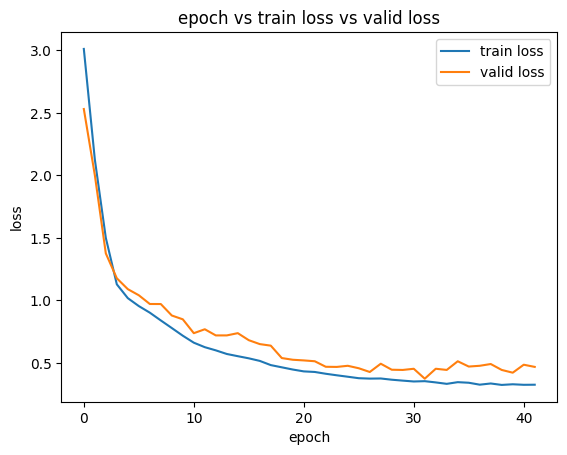

plot done
=== V4 hdfs seed=999 m=0.75 ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v4/LogBERT/output/hdfs/vocab.pkl
vocab Size:  20

Loading Train Dataset
before filtering short session
train size  4370
valid size  485


100%|██████████| 4855/4855 [00:00<00:00, 83513.84it/s]

Num of train seqs 4370
Num of valid seqs 485

Loading valid Dataset
Creating Dataloader


Building BERT model
Creating BERT Trainer
Total Parameters: 2120213
Training Start


start calculate center


100%|██████████| 15/15 [00:00<00:00, 72.02it/s]


...

Epoch: 37 | phase: train, loss=0.328418701667996
logkey loss: 0.31665618016439323, hyper loss: 0.11762521558386438

Epoch: 37 | phase: valid, loss=0.47606340448061624
logkey loss: 0.4648677359024684, hyper loss: 0.11195676326751709

Log saved


start calculate center


100%|██████████| 15/15 [00:00<00:00, 64.91it/s]


Epoch: 38 | phase: train, loss=0.32712064184905854
logkey loss: 0.31585740878739776, hyper loss: 0.11263234234031509

Epoch: 38 | phase: valid, loss=0.39196218152840934
logkey loss: 0.38121715088685354, hyper loss: 0.1074502189954122

Log saved


start calculate center


100%|██████████| 15/15 [00:00<00:00, 67.29it/s]


Epoch: 39 | phase: train, loss=0.3182151174063192
logkey loss: 0.3080389069064575, hyper loss: 0.10176211409270763

Epoch: 39 | phase: valid, loss=0.40936972995599114
logkey loss: 0.39943011800448097, hyper loss: 0.09939610660076141

Log saved
Early stopping


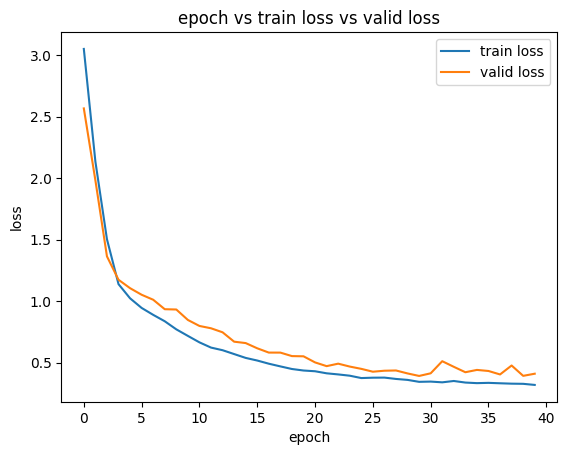

plot done
=== V4 bgl seed=1234 m=0.50 ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v4/LogBERT/output/bgl/vocab.pkl
vocab Size:  185

Loading Train Dataset
before filtering short session
train size  6013
valid size  668


100%|██████████| 6681/6681 [00:03<00:00, 1817.20it/s]


Num of train seqs 6013
Num of valid seqs 668

Loading valid Dataset
Creating Dataloader
Building BERT model
Creating BERT Trainer
Total Parameters: 2204858
Training Start


start calculate center


100%|██████████| 20/20 [00:00<00:00, 24.81it/s]


Epoch: 0 | phase: train, loss=5.3338374862058915
logkey loss: 5.207157520049396, hyper loss: 1.2667996838768536

Epoch: 0 | phase: valid, loss=4.391735446453095
logkey loss: 4.257713723182678, hyper loss: 1.3402166843414307

Log saved
 Model Saved on: /kaggle/working/.logbert_v4/LogBERT/output/bgl/v4/seed1234/m0p50/best_bert.pth


start calculate center


...

Epoch: 100 | phase: train, loss=0.41598429176259166
logkey loss: 0.4070341805603734, hyper loss: 0.08950112174379635

Epoch: 100 | phase: valid, loss=0.5214737959206104
logkey loss: 0.510336684435606, hyper loss: 0.1113711554557085

Log saved


start calculate center


100%|██████████| 20/20 [00:00<00:00, 25.70it/s]


Epoch: 101 | phase: train, loss=0.41245880272777324
logkey loss: 0.40389761692261633, hyper loss: 0.08561185321068382

Epoch: 101 | phase: valid, loss=0.518139073997736
logkey loss: 0.5051847897469998, hyper loss: 0.12954287342727183

Log saved


start calculate center


100%|██████████| 20/20 [00:00<00:00, 25.48it/s]


Epoch: 102 | phase: train, loss=0.41783646065841384
logkey loss: 0.4088483927622039, hyper loss: 0.08988068412172603

Epoch: 102 | phase: valid, loss=0.5240409761667252
logkey loss: 0.5123513840138912, hyper loss: 0.11689588204026222

Log saved
Early stopping


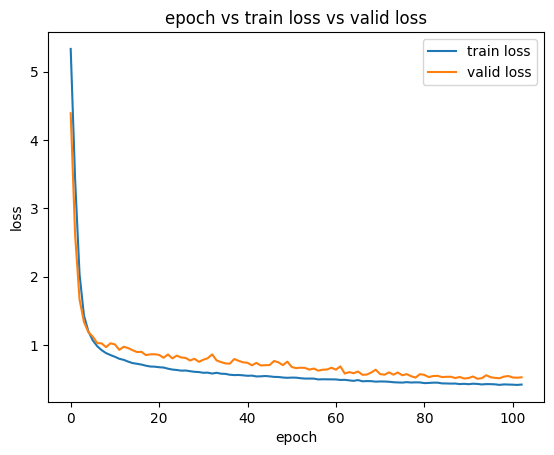

plot done
=== V4 bgl seed=2026 m=0.50 ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v4/LogBERT/output/bgl/vocab.pkl
vocab Size:  185

Loading Train Dataset
before filtering short session
train size  6013
valid size  668


100%|██████████| 6681/6681 [00:03<00:00, 1889.31it/s]


Num of train seqs 6013
Num of valid seqs 668

Loading valid Dataset
Creating Dataloader
Building BERT model
Creating BERT Trainer
Total Parameters: 2204858
Training Start


start calculate center


100%|██████████| 20/20 [00:00<00:00, 25.80it/s]


Epoch: 0 | phase: train, loss=5.164422893269177
logkey loss: 5.024119263664287, hyper loss: 1.4030362673621763

Epoch: 0 | phase: valid, loss=4.304176664352417
logkey loss: 4.157434785366059, hyper loss: 1.4674187362194062

Log saved
 Model Saved on: /kaggle/working/.logbert_v4/LogBERT/output/bgl/v4/seed2026/m0p50/best_bert.pth


start calculate center


...

Epoch: 52 | phase: train, loss=0.5139582127053789
logkey loss: 0.5008495240646569, hyper loss: 0.1310868697928235

Epoch: 52 | phase: valid, loss=0.6708231180906296
logkey loss: 0.6487960830330849, hyper loss: 0.22027034237980841

Log saved


start calculate center


100%|██████████| 20/20 [00:00<00:00, 24.95it/s]


Epoch: 53 | phase: train, loss=0.5129667596622585
logkey loss: 0.49968643392869494, hyper loss: 0.13280326223628405

Epoch: 53 | phase: valid, loss=0.6896059453487396
logkey loss: 0.6661688812077046, hyper loss: 0.23437060490250589

Log saved


start calculate center


100%|██████████| 20/20 [00:00<00:00, 26.23it/s]


Epoch: 54 | phase: train, loss=0.5078564362331508
logkey loss: 0.49470370673240827, hyper loss: 0.13152730839456467

Epoch: 54 | phase: valid, loss=0.709827471524477
logkey loss: 0.6882598146796226, hyper loss: 0.21567652150988578

Log saved
Early stopping


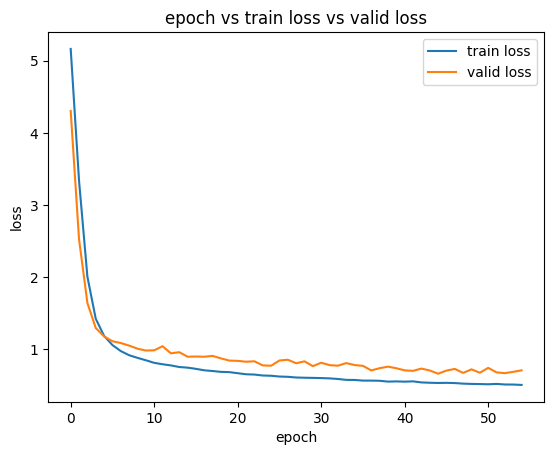

plot done
=== V4 bgl seed=999 m=0.50 ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v4/LogBERT/output/bgl/vocab.pkl
vocab Size:  185

Loading Train Dataset
before filtering short session
train size  6013
valid size  668


100%|██████████| 6681/6681 [00:03<00:00, 1879.73it/s]


Num of train seqs 6013
Num of valid seqs 668

Loading valid Dataset
Creating Dataloader
Building BERT model
Creating BERT Trainer
Total Parameters: 2204858
Training Start


start calculate center


100%|██████████| 20/20 [00:00<00:00, 26.01it/s]


Epoch: 0 | phase: train, loss=5.189094704102705
logkey loss: 5.0458544346100505, hyper loss: 1.4324025910168408

Epoch: 0 | phase: valid, loss=4.366575765609741
logkey loss: 4.215082371234894, hyper loss: 1.5149340629577637

Log saved
 Model Saved on: /kaggle/working/.logbert_v4/LogBERT/output/bgl/v4/seed999/m0p50/best_bert.pth


start calculate center


...

Epoch: 117 | phase: train, loss=0.3944433071516096
logkey loss: 0.3881742080803064, hyper loss: 0.06269098368079905

Epoch: 117 | phase: valid, loss=0.5247063413262367
logkey loss: 0.516535846143961, hyper loss: 0.08170495517551898

Log saved


start calculate center


100%|██████████| 20/20 [00:00<00:00, 25.80it/s]


Epoch: 118 | phase: train, loss=0.395428572885971
logkey loss: 0.38917539257775335, hyper loss: 0.06253179413749572

Epoch: 118 | phase: valid, loss=0.4854851059615612
logkey loss: 0.47792854756116865, hyper loss: 0.07556561678647995

Log saved


start calculate center


100%|██████████| 20/20 [00:00<00:00, 25.57it/s]


Epoch: 119 | phase: train, loss=0.3882011447878764
logkey loss: 0.382097746111094, hyper loss: 0.061033977086053175

Epoch: 119 | phase: valid, loss=0.4770818330347538
logkey loss: 0.46900306865572927, hyper loss: 0.08078761696815491

Log saved
Early stopping


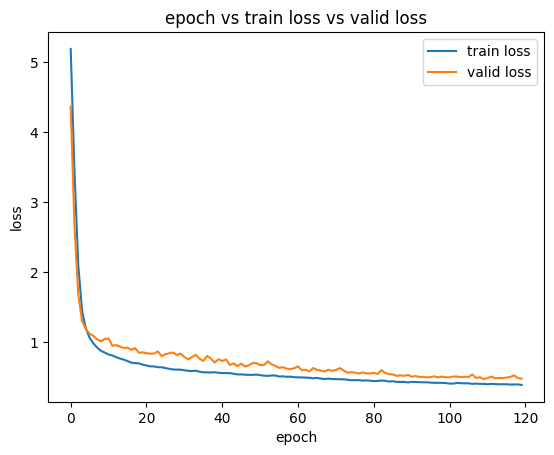

plot done
Modèles : ["('bgl', 1234)", "('bgl', 2026)", "('bgl', 999)", "('hdfs', 1234)", "('hdfs', 2026)", "('hdfs', 999)"]


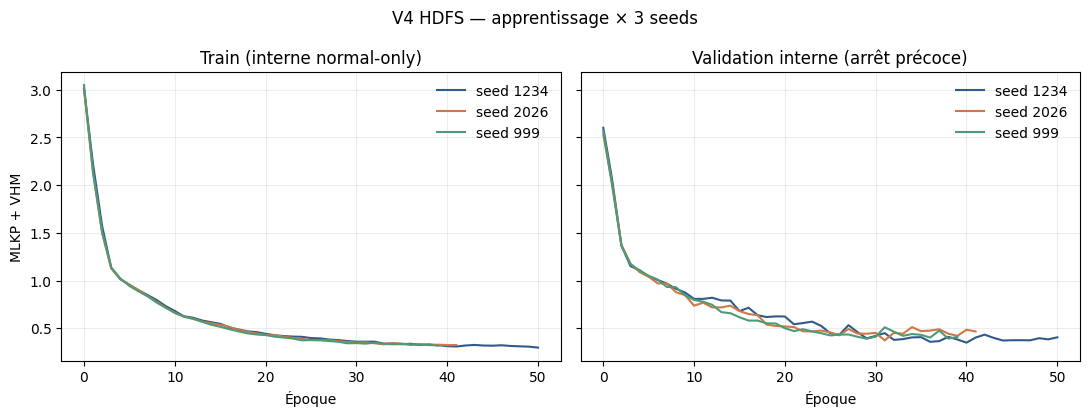

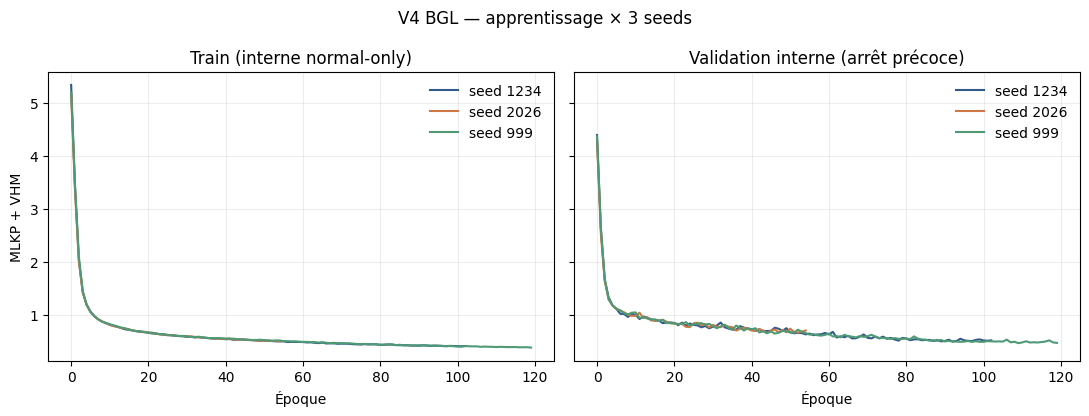

In [7]:
import matplotlib.pyplot as plt
from bert_pytorch import Trainer
from bert_pytorch.dataset.utils import seed_everything
from bert_pytorch.dataset import WordVocab

subprocess.run([sys.executable, "logbert.py", "vocab"], cwd=REPO_HDFS, check=True)
hdfs_vocab = WordVocab.load_vocab(str(OUTPUT_HDFS / "vocab.pkl"))
subprocess.run([sys.executable, "logbert.py", "vocab"], cwd=REPO_BGL, check=True)
bgl_vocab = WordVocab.load_vocab(str(OUTPUT_BGL / "vocab.pkl"))
print("Vocabs train-only : HDFS", len(hdfs_vocab), "| BGL", len(bgl_vocab))

spec_h = importlib.util.spec_from_file_location("hdfs_cfg_v4", REPO_HDFS / "logbert.py")
cfg_h = importlib.util.module_from_spec(spec_h); spec_h.loader.exec_module(cfg_h)
spec_b = importlib.util.spec_from_file_location("bgl_cfg_v4", REPO_BGL / "logbert.py")
cfg_b = importlib.util.module_from_spec(spec_b); spec_b.loader.exec_module(cfg_b)
CFGS = {"hdfs": (cfg_h, OUTPUT_HDFS, HDFS_M), "bgl": (cfg_b, OUTPUT_BGL, BGL_M)}
G_GRIDS = {"hdfs": [g for g in G_GRID if g <= len(hdfs_vocab)],
           "bgl": [g for g in G_GRID if g <= len(bgl_vocab)]}

def v4_train(ds, seed, mask_ratio):
    cfg, outdir, _ = CFGS[ds]
    model_dir = outdir / "v4" / f"seed{seed}" / ("m%.2f" % mask_ratio).replace(".", "p")
    model_dir.mkdir(parents=True, exist_ok=True)
    options = cfg.options.copy()
    options.update({"device": "cuda" if torch.cuda.is_available() else "cpu",
                    "output_dir": str(outdir) + "/", "model_dir": str(model_dir) + "/",
                    "model_path": str(model_dir / "best_bert.pth"),
                    "vocab_path": str(outdir / "vocab.pkl"),
                    "scale_path": str(model_dir / "scale.pkl"),
                    "mask_ratio": mask_ratio, "num_workers": 2, "on_memory": True})
    seed_everything(seed=seed)
    ckpt = Path(options["model_path"])
    if ckpt.exists():
        print(f"{ds} seed={seed} m={mask_ratio:.2f} : reprise.")
    else:
        print(f"=== V4 {ds} seed={seed} m={mask_ratio:.2f} ===")
        t = Trainer(options); t.train(); del t
        assert ckpt.exists(), "Checkpoint manquant."
    try:
        model = torch.load(str(ckpt), map_location=options["device"], weights_only=False)
    except TypeError:
        model = torch.load(str(ckpt), map_location=options["device"])
    model.to(options["device"]); model.eval()
    return model, options

VOCABS = {"hdfs": hdfs_vocab, "bgl": bgl_vocab}
MODELS, OPTIONS = {}, {}
if RUN_HDFS:
    for _s in V4_SEEDS:
        _m, _o = v4_train("hdfs", _s, HDFS_M)
        MODELS[("hdfs", _s)], OPTIONS[("hdfs", _s)] = _m, _o
        del _m
if RUN_BGL:
    for _s in V4_SEEDS:
        _m, _o = v4_train("bgl", _s, BGL_M)
        MODELS[("bgl", _s)], OPTIONS[("bgl", _s)] = _m, _o
        del _m
print("Modèles :", sorted(str(k) for k in MODELS))

for _ds, _out in [("hdfs", OUTPUT_HDFS), ("bgl", OUTPUT_BGL)]:
    if not any(k[0] == _ds for k in MODELS):
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    _cols = ["#315A8A", "#D07845", "#4E9A75"]
    for _i, _s in enumerate(V4_SEEDS):
        _d = _out / "v4" / f"seed{_s}" / ("m%.2f" % CFGS[_ds][2]).replace(".", "p")
        _tr = pd.read_csv(_d / "train_log2.csv"); _va = pd.read_csv(_d / "valid_log2.csv")
        axes[0].plot(_tr.epoch, _tr.loss, color=_cols[_i % 3], label=f"seed {_s}")
        axes[1].plot(_va.epoch, _va.loss, color=_cols[_i % 3], label=f"seed {_s}")
    axes[0].set_title("Train (interne normal-only)"); axes[1].set_title("Validation interne (arrêt précoce)")
    for _ax in axes:
        _ax.set_xlabel("Époque"); _ax.grid(alpha=.22); _ax.legend(frameon=False)
    axes[0].set_ylabel("MLKP + VHM")
    fig.suptitle(f"V4 {_ds.upper()} — apprentissage × 3 seeds")
    fig.tight_layout(); fig.savefig(WORK_DIR / f"v4_loss_{_ds}.png", dpi=200, bbox_inches="tight"); plt.show()


## 8. Sélection validation-only + tests verrouillés (HDFS + BGL)

Scoring paper-style identique V2/V3. Jeux : calibration supervisée = `val_normal`/`val_abnormal` (sélection) ; validation interne normal-only du Trainer = arrêt précoce uniquement (C2).


In [8]:
from bert_pytorch.dataset import LogDataset
from bert_pytorch import Predictor
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from scipy.stats import norm

def v4_scores_by_g(model, options, vocab, filename, seed, g_grid):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    predictor = Predictor(options)
    log_seqs, time_seqs = predictor.generate_test(
        options["output_dir"], filename, predictor.window_size,
        predictor.adaptive_window, predictor.seq_len, None, predictor.min_len)
    dataset = LogDataset(log_seqs, time_seqs, vocab, seq_len=predictor.seq_len,
                         corpus_lines=predictor.corpus_lines, on_memory=False,
                         predict_mode=True, mask_ratio=options["mask_ratio"])
    loader = DataLoader(dataset, batch_size=predictor.batch_size,
                        num_workers=predictor.num_workers, collate_fn=dataset.collate_fn)
    errors = {g: [] for g in g_grid}
    n_masked = []
    for bi, batch in enumerate(loader):
        batch = {k: v.to(options["device"]) for k, v in batch.items()}
        with torch.no_grad():
            logits = model(batch["bert_input"], batch["time_input"])["logkey_output"]
        labels = batch["bert_label"]
        for i in range(len(labels)):
            mask = labels[i] > 0
            tgt = labels[i][mask]
            n_masked.append(len(tgt))
            if len(tgt):
                top = torch.topk(logits[i][mask], k=max(g_grid), dim=-1).indices
                mt = top == tgt.unsqueeze(1)
                for g in g_grid:
                    errors[g].append(int((~mt[:, :g].any(dim=1)).sum().item()))
            else:
                for g in g_grid:
                    errors[g].append(0)
    den = np.maximum(np.asarray(n_masked, dtype=float), 1)
    return {g: np.asarray(errors[g], dtype=float) / den for g in g_grid}

def v4_metrics(y, score, r, prior):
    pred = (score > r).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    rec = tp / max(tp + fn, 1)
    fpr = fp / max(fp + tn, 1)
    prec = prior * rec / max(prior * rec + (1 - prior) * fpr, 1e-12)
    f1 = 2 * prec * rec / max(prec + rec, 1e-12)
    return {"Precision_target": prec, "Recall": rec, "F1_target": f1, "FPR": fpr,
            "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}

def v4_wilson(s, t, c=0.95):
    if t <= 0:
        return [float("nan"), float("nan")]
    z = norm.ppf(.5 + c / 2); p = s / t; den = 1 + z * z / t
    ce = (p + z * z / (2 * t)) / den
    ha = z * np.sqrt(p * (1 - p) / t + z * z / (4 * t * t)) / den
    return [max(0., ce - ha), min(1., ce + ha)]

def v4_select(ds, seed, counts, prior):
    model, opts = MODELS[(ds, seed)], OPTIONS[(ds, seed)]
    vocab, gg = VOCABS[ds], G_GRIDS[ds]
    yv = np.r_[np.zeros(counts["val_normal"], dtype=int), np.ones(counts["val_abnormal"], dtype=int)]
    vn = v4_scores_by_g(model, opts, vocab, "val_normal", 1234, gg)
    va = v4_scores_by_g(model, opts, vocab, "val_abnormal", 1235, gg)
    rows = []
    for g in gg:
        sc = np.r_[vn[g], va[g]]
        for r in R_GRID:
            rows.append({"m": opts["mask_ratio"], "g": g, "r": float(r), **v4_metrics(yv, sc, r, prior)})
    search = pd.DataFrame(rows)
    b = search.sort_values(["F1_target", "Recall", "Precision_target"], ascending=False).iloc[0]
    sel = {"m": float(b.m), "g": int(b.g), "r": float(b.r), "val_F1": float(b.F1_target),
           "val_P": float(b.Precision_target), "val_R": float(b.Recall)}
    search.to_csv(WORK_DIR / f"v4_search_{ds}_seed{seed}.csv", index=False)
    return sel

def v4_test(ds, seed, sel, counts, prior):
    model, opts = MODELS[(ds, seed)], OPTIONS[(ds, seed)]
    vocab = VOCABS[ds]
    yt = np.r_[np.zeros(counts["test_normal"], dtype=int), np.ones(counts["test_abnormal"], dtype=int)]
    tn_ = v4_scores_by_g(model, opts, vocab, "test_normal", 1236, [sel["g"]])
    ta_ = v4_scores_by_g(model, opts, vocab, "test_abnormal", 1237, [sel["g"]])
    sc = np.r_[tn_[sel["g"]], ta_[sel["g"]]]
    pr = (sc > sel["r"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pr, labels=[0, 1]).ravel()
    return {"seed": seed, "m": sel["m"], "g": sel["g"], "r": sel["r"],
            "Precision": float(precision_score(yt, pr, zero_division=0)),
            "Recall": float(recall_score(yt, pr, zero_division=0)),
            "F1": float(f1_score(yt, pr, zero_division=0)),
            "FPR": float(fp / max(tn + fp, 1)), "TP": int(tp), "FP": int(fp),
            "FN": int(fn), "TN": int(tn),
            "ROC_AUC": float(roc_auc_score(yt, sc)), "PR_AUC": float(average_precision_score(yt, sc)),
            "test_prev": float(yt.mean()),
            "P_CI95": v4_wilson(tp, tp + fp), "R_CI95": v4_wilson(tp, tp + fn)}, sc, yt

V4_SEL, V4_TEST, V4_SCORES = {}, {}, {}
for _ds, _counts, _prior, _run in [("hdfs", HDFS_COUNTS, HDFS_PRIOR, RUN_HDFS),
                                   ("bgl", BGL_COUNTS, BGL_PRIOR, RUN_BGL)]:
    if not _run:
        continue
    for _s in V4_SEEDS:
        _sel = v4_select(_ds, _s, _counts, _prior)
        _res, _sc, _yt = v4_test(_ds, _s, _sel, _counts, _prior)
        V4_SEL[(_ds, _s)], V4_TEST[(_ds, _s)] = _sel, _res
        V4_SCORES[(_ds, _s)] = {"scores": _sc, "y": _yt}
        print(_ds, _s, "sel", {k: round(_sel[k], 4) if isinstance(_sel[k], float) else _sel[k] for k in ["m", "g", "r", "val_F1"]},
              "test F1=%.4f P=%.4f R=%.4f" % (_res["F1"], _res["Precision"], _res["Recall"]))
np.savez(WORK_DIR / "v4_test_scores.npz",
         **{f"{d}_{s}": V4_SCORES[(d, s)]["scores"] for d, s in V4_SCORES},
         **{f"y_{d}": V4_SCORES[(d, V4_SEEDS[0])]["y"] for d in ["hdfs", "bgl"] if (d, V4_SEEDS[0]) in V4_SCORES})
print("Sélections + tests sauvés.")


55336it [00:00, 79861.51it/s]


val_normal size: 55336


2139it [00:00, 64672.88it/s]

val_abnormal size: 2139



498032it [00:06, 77928.21it/s]


...


9053it [00:04, 1938.08it/s]

test_normal size: 9053



2091it [00:00, 2148.02it/s]

test_abnormal size: 2091


bgl 999 sel {'m': 0.5, 'g': 15, 'r': 0.01, 'val_F1': 0.921} test F1=0.9142 P=0.9112 R=0.9173
Sélections + tests sauvés.


## 9. Inférence robuste : variance du tirage + multi-passes déterministes (W3)

W3.1 : même modèle HDFS, 5 seeds d'inférence → part de variance due au seul masquage. W3.2 : passes complémentaires round-robin (K=4 à `m=0.75`, K=2 à `m=0.50`) : chaque position est masquée K−1 fois, couverture 100 % garantie par construction, aléa supprimé.


In [9]:
from bert_pytorch.dataset import LogDataset as _BaseLogDataset

class DeterministicLogDataset(_BaseLogDataset):
    def __init__(self, *a, masks=None, **k):
        super().__init__(*a, **k)
        self.masks = masks
    def __getitem__(self, idx):
        k, t = self.log_corpus[idx], self.time_corpus[idx]
        mask = self.masks[idx]
        toks = [self.vocab.stoi.get(tok, self.vocab.unk_index) for tok in k]
        lab, ti, tl = [], list(t), []
        for i, tok in enumerate(k):
            if i in mask:
                lab.append(self.vocab.stoi.get(tok, self.vocab.unk_index))
                toks[i] = self.vocab.mask_index
                tl.append(ti[i]); ti[i] = 0
            else:
                lab.append(0); tl.append(0)
        return [self.vocab.sos_index] + toks, [self.vocab.pad_index] + lab, [0] + ti, [self.vocab.pad_index] + tl

def v4_round_robin_masks(n, K):
    return [{i for i in range(n) if i % K != k} for k in range(K)]

def v4_multipass_scores(ds, seed, g, K):
    model, opts = MODELS[(ds, seed)], OPTIONS[(ds, seed)]
    vocab = VOCABS[ds]
    from bert_pytorch import Predictor as _P
    out = {}
    for fname in ["test_normal", "test_abnormal"]:
        pred = _P(opts)
        ls, ts = pred.generate_test(opts["output_dir"], fname, pred.window_size,
                                    pred.adaptive_window, pred.seq_len, None, pred.min_len)
        masks = [v4_round_robin_masks(len(s), K)[0] for s in ls]
        errs, nm = [], []
        for k in range(K):
            masks_k = [v4_round_robin_masks(len(s), K)[k] for s in ls]
            dset = DeterministicLogDataset(ls, ts, vocab, seq_len=pred.seq_len, corpus_lines=len(ls),
                                           on_memory=False, predict_mode=True, masks=masks_k)
            from torch.utils.data import DataLoader as _DL
            loader = _DL(dset, batch_size=pred.batch_size, num_workers=0, collate_fn=dset.collate_fn)
            e_k = np.zeros(len(ls)); m_k = np.zeros(len(ls))
            base = 0
            for batch in loader:
                bsz = len(batch["bert_label"])
                batch = {kk: vv.to(opts["device"]) for kk, vv in batch.items()}
                with torch.no_grad():
                    logits = model(batch["bert_input"], batch["time_input"])["logkey_output"]
                for i in range(bsz):
                    mk = batch["bert_label"][i] > 0
                    tg = batch["bert_label"][i][mk]
                    if len(tg):
                        top = torch.topk(logits[i][mk], k=g, dim=-1).indices
                        e_k[base + i] = int((~((top == tg.unsqueeze(1))[:, :g].any(dim=1))).sum().item())
                        m_k[base + i] = len(tg)
                base += bsz
            errs.append(e_k); nm.append(m_k)
        E = np.stack(errs).sum(0); M = np.stack(nm).sum(0)
        out[fname] = E / np.maximum(M, 1)
        assert (M > 0).all(), "Couverture incomplète."
    return out

V4_MP = {}
if RUN_MULTIPASS and RUN_HDFS:
    # W3.1 : variance du tirage unique (5 seeds d'inférence, modèle seed 1234).
    _s0, _sel0 = V4_SEEDS[0], V4_SEL[("hdfs", V4_SEEDS[0])]
    _f1s = []
    for _iseed in [11, 22, 33, 44, 55]:
        _n = v4_scores_by_g(MODELS[("hdfs", _s0)], OPTIONS[("hdfs", _s0)], VOCABS["hdfs"], "test_normal", _iseed, [_sel0["g"]])
        _a = v4_scores_by_g(MODELS[("hdfs", _s0)], OPTIONS[("hdfs", _s0)], VOCABS["hdfs"], "test_abnormal", _iseed + 1, [_sel0["g"]])
        _sc = np.r_[_n[_sel0["g"]], _a[_sel0["g"]]]
        _yt = np.r_[np.zeros(HDFS_COUNTS["test_normal"], dtype=int), np.ones(HDFS_COUNTS["test_abnormal"], dtype=int)]
        _f1s.append(float(f1_score(_yt, (_sc > _sel0["r"]).astype(int), zero_division=0)))
    print("W3.1 tirage unique HDFS : F1 =", [round(v, 4) for v in _f1s], "std=%.4f" % float(np.std(_f1s, ddof=1)))
    V4_MP["single_pass_spread"] = _f1s
    # W3.2 : multi-passes déterministes, même seuil r.
    for _ds, _K in [("hdfs", 4), ("bgl", 2)]:
        for _s in V4_SEEDS:
            _sel = V4_SEL[(_ds, _s)]
            _mp = v4_multipass_scores(_ds, _s, _sel["g"], _K)
            _counts = HDFS_COUNTS if _ds == "hdfs" else BGL_COUNTS
            _yt = np.r_[np.zeros(_counts["test_normal"], dtype=int), np.ones(_counts["test_abnormal"], dtype=int)]
            _sc = np.r_[_mp["test_normal"], _mp["test_abnormal"]]
            _pr = (_sc > _sel["r"]).astype(int)
            V4_MP[(_ds, _s)] = {"F1": float(f1_score(_yt, _pr, zero_division=0)),
                                "P": float(precision_score(_yt, _pr, zero_division=0)),
                                "R": float(recall_score(_yt, _pr, zero_division=0))}
            print(f"W3.2 {_ds} seed {_s} K={_K} : F1={V4_MP[(_ds,_s)]['F1']:.4f} (single={V4_TEST[(_ds,_s)]['F1']:.4f})")
    np.savez(WORK_DIR / "v4_multipass.npz", **{f"{k[0]}_{k[1]}": np.array([V4_MP[k][kk] for kk in ["F1", "P", "R"]]) for k in V4_MP if isinstance(k, tuple)})
    print("Multi-passes sauvés.")


498032it [00:06, 80827.15it/s]


test_normal size: 498032


8508it [00:00, 66511.98it/s]

test_abnormal size: 8508



498032it [00:06, 80164.10it/s]


...

test_abnormal size: 2091
W3.2 bgl seed 2026 K=2 : F1=0.9105 (single=0.9072)


9053it [00:04, 1923.69it/s]


test_normal size: 9053


2091it [00:00, 2156.78it/s]


test_abnormal size: 2091
W3.2 bgl seed 999 K=2 : F1=0.9196 (single=0.9142)
Multi-passes sauvés.


## 10. Routeur hybride : Fast-Path courts + paliers de longueur (W1.2, I2)

Règle Fast-Path sur `short_*` : anomalie ssi template `FATAL` (insensible à la casse) ou clé hors vocabulaire train ; sinon normal. Paliers LogBERT : `10–50` multi-passes, `≥50` standard. Comparaison honnête : baseline = shorts prédits normaux (invisibles au pipeline actuel).


In [11]:
V4_ROUTER = {}
if RUN_ROUTER:
    _TPLMAPS = {"hdfs": {}, "bgl": {}}
    _hc = OUTPUT_HDFS / "HDFS.log_templates.csv"
    _hj = OUTPUT_HDFS / "hdfs_log_templates.json"
    if _hc.exists() and _hj.exists():
        try:
            _tdf = pd.read_csv(_hc, usecols=["EventId", "EventTemplate"])
            _h2t = dict(zip(_tdf.EventId.astype(str), _tdf.EventTemplate.astype(str)))
            for _h, _i in json.loads(_hj.read_text(encoding="utf-8")).items():
                if str(_h) in _h2t:
                    _TPLMAPS["hdfs"][str(int(_i))] = _h2t[str(_h)]
        except Exception as _e:
            print("Carte templates HDFS :", _e)
    _bc = OUTPUT_BGL / "BGL.log_templates.csv"
    if _bc.exists():
        try:
            _tdf = pd.read_csv(_bc, usecols=["EventId", "EventTemplate"]).drop_duplicates("EventId")
            _TPLMAPS["bgl"] = dict(zip(_tdf.EventId.astype(str), _tdf.EventTemplate.astype(str)))
        except Exception as _e:
            print("Carte templates BGL :", _e)
    print("Templates chargés :", {k: len(v) for k, v in _TPLMAPS.items()})
    for _ds, _counts, _outdir, _col in [("hdfs", HDFS_COUNTS, OUTPUT_HDFS, "events"),
                                        ("bgl", BGL_COUNTS, OUTPUT_BGL, "EventId")]:
        if (_ds, V4_SEEDS[0]) not in V4_TEST:
            continue
        _tpl_map = _TPLMAPS[_ds]
        _vocab = VOCABS[_ds]
        def _feats(line):
            toks = line.split()
            oov = any(t not in _vocab.stoi for t in toks)
            fatal = any("fatal" in str(_tpl_map.get(t, "")).lower() for t in toks)
            return len(toks), oov, fatal
        for _part in ["short_normal", "short_abnormal"]:
            _path = _outdir / _part
            if not _path.exists():
                continue
        _dec, _y = [], []
        for _part, _lab in [("short_normal", 0), ("short_abnormal", 1)]:
            with open(_outdir / _part, encoding="utf-8") as _f:
                for _line in _f:
                    _line = _line.strip()
                    if not _line:
                        continue
                    _, _oov, _fatal = _feats(_line)
                    _dec.append(1 if (_oov or _fatal) else 0)
                    _y.append(_lab)
        _dec = np.asarray(_dec); _y = np.asarray(_y)
        from sklearn.metrics import precision_score as _ps, recall_score as _rs, f1_score as _f1
        _rp = float(_ps(_y, _dec, zero_division=0)); _rr = float(_rs(_y, _dec, zero_division=0))
        V4_ROUTER[(_ds, "fastpath")] = {"P": _rp, "R": _rr, "F1": float(_f1(_y, _dec, zero_division=0)),
                                        "n_short": int(len(_y)), "n_anom": int(_y.sum())}
        print(f"{_ds} Fast-Path shorts (n={len(_y)}, anom={int(_y.sum())}) : P={_rp:.4f} R={_rr:.4f} F1={V4_ROUTER[(_ds,'fastpath')]['F1']:.4f}")
        # Combiné : baseline (shorts=normaux) vs routeur (fast-path + paliers LogBERT).
        _base_y, _base_p, _rou_y, _rou_p = [], [], [], []
        for _s in V4_SEEDS:
            _sel = V4_SEL[(_ds, _s)]
            _sc = V4_SCORES[(_ds, _s)]["scores"]
            _yy = V4_SCORES[(_ds, _s)]["y"]
            _bp = (_sc > _sel["r"]).astype(int)
            _base_y.append(np.r_[_yy, _y]); _base_p.append(np.r_[_bp, np.zeros(_y.shape[0], dtype=int)])
            _rou_y.append(np.r_[_yy, _y]); _rou_p.append(np.r_[_bp, _dec])
        def _agg(ys, ps):
            from sklearn.metrics import precision_score as _p2, recall_score as _r2, f1_score as _f2
            return [(float(_p2(a, b, zero_division=0)), float(_r2(a, b, zero_division=0)), float(_f2(a, b, zero_division=0))) for a, b in zip(ys, ps)]
        _b = np.mean(_agg(_base_y, _base_p), axis=0); _r = np.mean(_agg(_rou_y, _rou_p), axis=0)
        V4_ROUTER[(_ds, "combined")] = {"base_P": float(_b[0]), "base_R": float(_b[1]), "base_F1": float(_b[2]),
                                        "router_P": float(_r[0]), "router_R": float(_r[1]), "router_F1": float(_r[2])}
        print(f"{_ds} combiné shorts inclus — baseline P/R/F1={_b[0]:.4f}/{_b[1]:.4f}/{_b[2]:.4f} | routeur={_r[0]:.4f}/{_r[1]:.4f}/{_r[2]:.4f}")
    (WORK_DIR / "v4_router.json").write_text(json.dumps({f"{k[0]}_{k[1]}": v for k, v in V4_ROUTER.items()}, indent=2, default=str), encoding="utf-8")
    print("Routeur sauvé.")

Templates chargés : {'hdfs': 47, 'bgl': 1000}
hdfs Fast-Path shorts (n=6191, anom=6191) : P=1.0000 R=0.5235 F1=0.6872
hdfs combiné shorts inclus — baseline P/R/F1=0.7522/0.4668/0.5745 | routeur=0.8163/0.6873/0.7451
bgl Fast-Path shorts (n=17945, anom=392) : P=0.9080 R=0.9566 F1=0.9317
bgl combiné shorts inclus — baseline P/R/F1=0.9045/0.7719/0.8330 | routeur=0.9051/0.9229/0.9139
Routeur sauvé.


## 11. SLM : évidence enrichie paramètres (I3) + harnais d'évaluation (W2)

`inference.py` v4 accepte `session_params` (listes de paramètres bruts alignées sur les tokens) et les expose en `observed_parameters` dans l'évidence. HDFS : paramètres exacts retrouvés par `BlockId` dans le CSV structuré ; BGL : exemples par template. Le harnais note le SLM sur `v4_slm_labels.csv` s'il existe (JSON valide, événements ancrés, action attendue), sinon smoke démo + temps/appel mesuré (S3/W2.3).


In [23]:
import time as _t
V4_SLM = {"timings": []}
if RUN_SLM:
    %pip install -q -U "regex>=2025.10.22"
    print("regex mis à jour pour transformers (parsing Drain terminé, sans impact).")
    from transformers import AutoTokenizer, AutoModelForCausalLM
    SLM_ID = os.environ.get("V4_SLM_ID", "Qwen/Qwen2.5-1.5B-Instruct")
    _tok = AutoTokenizer.from_pretrained(SLM_ID, trust_remote_code=True)
    _slm = AutoModelForCausalLM.from_pretrained(
        SLM_ID, trust_remote_code=True,
        dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        device_map="auto", low_cpu_mem_usage=True).eval()
    SYSTEM = ("Tu es un ingenieur SRE. LogBERT a classe cette session (voir statut_logbert : anormale ou normale). "
              "Explique pour un ingenieur d'astreinte, de facon concise (moins de 250 mots). "
              "Reponds UNIQUEMENT avec un objet JSON valide, sans texte avant ni apres, avec exactement ces cles non accentuees, dans cet ordre : "
              "evenements_cites, resume_ingenieur, lecture_logbert, chaine_causale_probable, incertitudes, "
              "actions_recommandees. "
              "0) MONDE FERME : tu ne disposes d'AUCUNE autre information que ce dossier transmis par LogBERT (tokens, templates, lignes brutes, score). N'utilise aucune connaissance exterieure sur les systemes ; toute valeur, adresse ou cause absente du dossier est INTERDITE dans ta reponse. Ton role : analyser et traduire le diagnostic, jamais l'enrichir. "
              "REGLES STRICTES : "
              "1) evenements_cites est OBLIGATOIRE (au plus 12 elements) : chaque element est soit un EventId recopie a l'identique depuis tokens_observes, soit une ligne brute ou un template recopie a l'identique (ne complete JAMAIS les <*> par des valeurs inventees). Aucune reformulation. "
              "2) actions_recommandees doit etre une LISTE d'objets {action, pourquoi, priorite}. "
              "3) chaine_causale_probable doit etre une chaine de texte, pas une liste. "
              "4) ne recopie jamais les lignes brutes hors de evenements_cites. "
              "Rappel final : la reponse doit COMMENCER par evenements_cites.")
    import re as _re2
    def _ask(dossier):
        prompt = _tok.apply_chat_template(
            [{"role": "system", "content": SYSTEM},
             {"role": "user", "content": json.dumps(dossier, ensure_ascii=False)[:3000]}],
            tokenize=False, add_generation_prompt=True)
        inputs = _tok(prompt, return_tensors="pt").to(_slm.device)
        _t0 = _t.time()
        with torch.no_grad():
            out = _slm.generate(**inputs, max_new_tokens=1024, do_sample=False)
        n_new = int(out.shape[1] - inputs.input_ids.shape[1])
        if n_new <= 0:
            print("Generation vide : second essai avec echantillonnage.")
            with torch.no_grad():
                out = _slm.generate(**inputs, max_new_tokens=1024, do_sample=True, temperature=0.7, top_p=0.9)
            n_new = int(out.shape[1] - inputs.input_ids.shape[1])
        dt = _t.time() - _t0
        raw = _tok.decode(out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True)
        V4_SLM["timings"].append(dt)
        V4_SLM["last_n_new"] = n_new
        raw = raw.replace("```json", "```").replace("```", "").strip()
        m = _re2.search(r"\{.*\}", raw, _re2.S)
        try:
            return json.loads(m.group(0)) if m else None, raw
        except Exception:
            return None, raw
    import unicodedata as _ud
    def _norm_key(k):
        k = "".join(c for c in _ud.normalize("NFKD", str(k)) if not _ud.combining(c))
        return "".join(c for c in k.lower() if c.isalnum())
    def _check_schema(toks, tpls, raws, p):
        toks = set(map(str, toks))
        tplset = set(map(str, tpls))
        rawset = set(map(str, raws)) if isinstance(raws, list) else set()
        bad = {"json_valide": False, "cles_completes": False, "actions_est_liste": False,
               "chaine_est_texte": False, "ancre_ids": False, "ancre_templates": False,
               "ancre_brutes": False, "evenements_ancres": False}
        if not isinstance(p, dict):
            return bad
        canon = {}
        for k, v in p.items():
            nk = _norm_key(k)
            if nk.startswith("resume"):
                canon["resume_ingenieur"] = v
            elif nk.startswith("lecture"):
                canon["lecture_logbert"] = v
            elif "causal" in nk or "chaine" in nk:
                canon["chaine_causale_probable"] = v
            elif nk.startswith("incertitude"):
                canon["incertitudes"] = v
            elif "action" in nk:
                canon["actions_recommandees"] = v
            elif "evenement" in nk or "event" in nk or nk == "cites":
                canon["evenements_cites"] = v
        if not canon:
            return bad
        cited = canon.get("evenements_cites", [])
        acts = canon.get("actions_recommandees", [])
        def _denorm(s):
            return " ".join(str(s).replace("<*>", " ").split())
        tplnorm = {_denorm(t) for t in tplset}
        def _hit(c):
            c = str(c)
            if c in toks:
                return "ids"
            if c in tplset or _denorm(c) in tplnorm:
                return "templates"
            for r in rawset:
                if c and (c in r or r in c):
                    return "brutes"
            return None
        hits = [_hit(c) for c in cited] if isinstance(cited, list) else []
        good = [h for h in hits if h]
        return {"json_valide": True,
                "cles_completes": all(k in canon for k in ["resume_ingenieur", "lecture_logbert", "chaine_causale_probable",
                                                           "incertitudes", "actions_recommandees", "evenements_cites"]),
                "actions_est_liste": isinstance(acts, list),
                "chaine_est_texte": isinstance(canon.get("chaine_causale_probable"), str),
                "ancre_ids": any(h == "ids" for h in good),
                "ancre_templates": any(h == "templates" for h in good),
                "ancre_brutes": any(h == "brutes" for h in good),
                "evenements_ancres": len(good) > 0}
    # Démo diagnostique : sessions de validation réelles + variables exactes réinjectées.
    # Projection assumée (pas de mesure terrain, pas de jeu annoté) : le fond est réel, l'évaluation reste qualitative.
    _demo = []
    _tplm = {"hdfs": {}, "bgl": {}}
    _hhc = OUTPUT_HDFS / "HDFS.log_templates.csv"
    _hhj = OUTPUT_HDFS / "hdfs_log_templates.json"
    if _hhc.exists() and _hhj.exists():
        try:
            _hdf = pd.read_csv(_hhc, usecols=["EventId", "EventTemplate"])
            _h2t = dict(zip(_hdf.EventId.astype(str), _hdf.EventTemplate.astype(str)))
            for _hh, _ii in json.loads(_hhj.read_text(encoding="utf-8")).items():
                if str(_hh) in _h2t:
                    _tplm["hdfs"][str(int(_ii))] = _h2t[str(_hh)]
        except Exception as _e:
            print("Carte HDFS :", _e)
    _bhc = OUTPUT_BGL / "BGL.log_templates.csv"
    if _bhc.exists():
        try:
            _bdf = pd.read_csv(_bhc, usecols=["EventId", "EventTemplate"]).drop_duplicates("EventId")
            _tplm["bgl"] = dict(zip(_bdf.EventId.astype(str), _bdf.EventTemplate.astype(str)))
        except Exception as _e:
            print("Carte BGL :", _e)
    print("Cartes templates (SLM) :", {k: len(v) for k, v in _tplm.items()})
    _struct_h = pd.read_csv(STRUCTURED_HDFS, usecols=["Content"])
    print("Contenu structuré :", len(_struct_h), "lignes (recherche BlockId par sous-chaîne, pas de colonne dédiée).")
    _cases = [("hdfs", h_va.iloc[0], 1), ("hdfs", h_vn.iloc[0], 0)]
    try:
        _cases += [("bgl", b_va.iloc[0], 1), ("bgl", b_vn.iloc[0], 0)]
    except Exception as _e:
        print("Démo BGL ignorée :", _e)
    for _ds, _fr, _lab in _cases:
        _toks = list(map(str, _fr.events if _ds == "hdfs" else _fr.EventId))[:40]
        _tpls = [str(_tplm.get(_ds, {}).get(t, t)) for t in _toks[:12]]
        if _ds == "hdfs":
            _blk = str(_fr.BlockId)
            _params = _struct_h.loc[_struct_h["Content"].str.contains(_blk, regex=False, na=False), "Content"].astype(str).tolist()[:12]
        else:
            _params = "AUCUNE (ne cite jamais cette phrase ; cite uniquement depuis tokens_observes et templates_observes)"
        _dossier = {"session_id": "demo-" + _ds + "-" + str(_lab), "dataset": _ds,
                    "tokens_observes": _toks, "templates_observes": _tpls,
                    "statut_logbert": "anormale" if _lab == 1 else "normale",
                    "lignes_brutes_exactes": _params}
        _parsed, _raw = _ask(_dossier)
        _tpfull = [str(_tplm.get(_ds, {}).get(t, t)) for t in _toks]
        _repaired = False
        if isinstance(_parsed, dict) and "evenements_cites" not in {k.lower() for k in _parsed}:
            print("Cites absents : appel de réparation ciblé.")
            _fix_prompt = _tok.apply_chat_template(
                [{"role": "system", "content": "Recopie UNIQUEMENT les EventId exacts depuis la liste fournie. Reponds UNIQUEMENT {evenements_cites: [...]}."},
                 {"role": "user", "content": "tokens_observes = " + json.dumps(_toks[:40], ensure_ascii=False)}],
                tokenize=False, add_generation_prompt=True)
            _fix_in = _tok(_fix_prompt, return_tensors="pt").to(_slm.device)
            _t0 = _t.time()
            with torch.no_grad():
                _fix_out = _slm.generate(**_fix_in, max_new_tokens=120, do_sample=False)
            V4_SLM.setdefault("repair_timings", []).append(_t.time() - _t0)
            _fix_raw = _tok.decode(_fix_out[0][_fix_in.input_ids.shape[1]:], skip_special_tokens=True)
            _fix_raw = _fix_raw.replace("```json", "```").replace("```", "").strip()
            _fix_m = _re2.search(r"\{.*\}", _fix_raw, _re2.S)
            try:
                _fix_p = json.loads(_fix_m.group(0)) if _fix_m else None
            except Exception:
                _fix_p = None
            if isinstance(_fix_p, dict):
                for _k, _v in _fix_p.items():
                    if "evenement" in _k.lower() or "event" in _k.lower():
                        _parsed["evenements_cites"] = _v
                        _repaired = True
        _rawl = _params if isinstance(_params, list) else []
        _schema = _check_schema(_toks, _tpfull, _rawl, _parsed)
        _schema["repare"] = bool(_repaired)
        _demo.append({"cas": _ds + "-" + str(_lab), "dossier": _dossier, "slm_json": _parsed,
                      "brut": _raw, "tokens_generes": V4_SLM.get("last_n_new"),
                      "json_valide": _schema["json_valide"],
                      "evenements_ancres": _schema.get("evenements_ancres", False),
                      "schema": _schema})
        print("demo", _ds, "label=" + str(_lab), ":", _schema, "(%.1fs)" % V4_SLM["timings"][-1])
    V4_SLM["demo"] = _demo
    if V4_SLM["timings"]:
        print("Temps moyen/appel (s) sur setup standard :", round(float(np.mean(V4_SLM["timings"])), 2))
    _lab = WORK_DIR / "v4_slm_labels.csv"
    if _lab.exists():
        print("Jeu annoté trouvé :", _lab, "— scoring W2.2 à implémenter sur ces dossiers.")
    else:
        print("v4_slm_labels.csv absent : smoke démo uniquement (constituer le jeu W2.1 avec l'équipe).")
    (WORK_DIR / "v4_slm.json").write_text(json.dumps(V4_SLM, indent=2, default=str), encoding="utf-8")


Note: you may need to restart the kernel to use updated packages.
regex mis à jour pour transformers (parsing Drain terminé, sans impact).


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Cartes templates (SLM) : {'hdfs': 47, 'bgl': 1000}
Contenu structuré : 11175629 lignes (recherche BlockId par sous-chaîne, pas de colonne dédiée).
demo hdfs label=1 : {'json_valide': True, 'cles_completes': True, 'actions_est_liste': True, 'chaine_est_texte': True, 'ancre_ids': False, 'ancre_templates': False, 'ancre_brutes': True, 'evenements_ancres': True, 'repare': False} (52.6s)
demo hdfs label=0 : {'json_valide': True, 'cles_completes': True, 'actions_est_liste': True, 'chaine_est_texte': True, 'ancre_ids': False, 'ancre_templates': False, 'ancre_brutes': True, 'evenements_ancres': True, 'repare': False} (51.4s)
demo bgl label=1 : {'json_valide': True, 'cles_completes': True, 'actions_est_liste': True, 'chaine_est_texte': True, 'ancre_ids': False, 'ancre_templates': True, 'ancre_brutes': False, 'evenements_ancres': True, 'repare': False} (13.8s)
demo bgl label=0 : {'json_valide': True, 'cles_completes': True, 'actions_est_liste': True, 'chaine_est_texte': True, 'ancre_ids': False,

## 12. Diagnostics : confusion, ROC/PR, variance, routeur, croisé


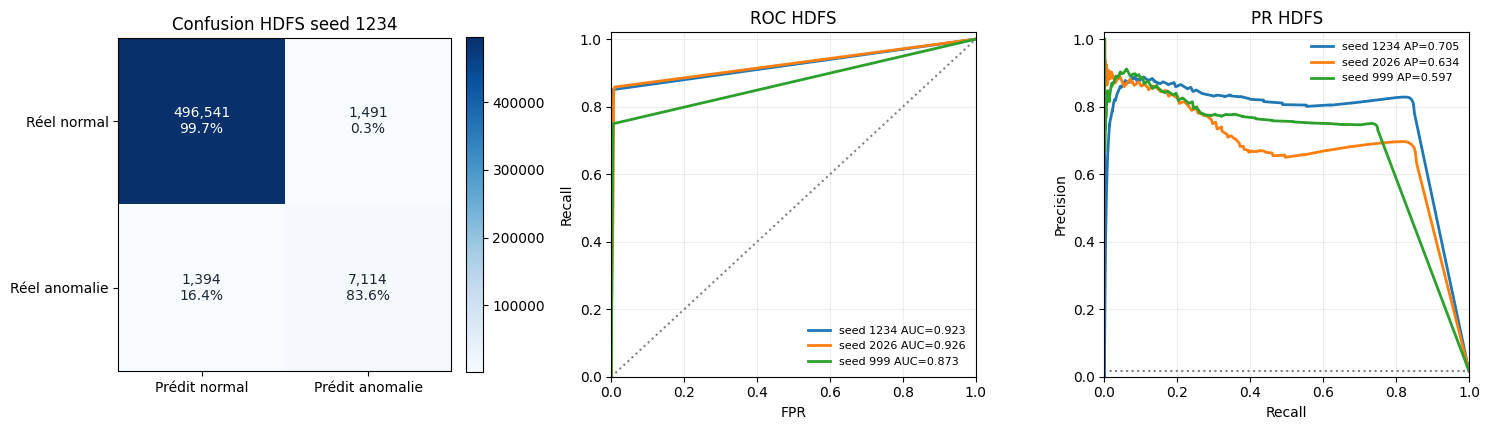

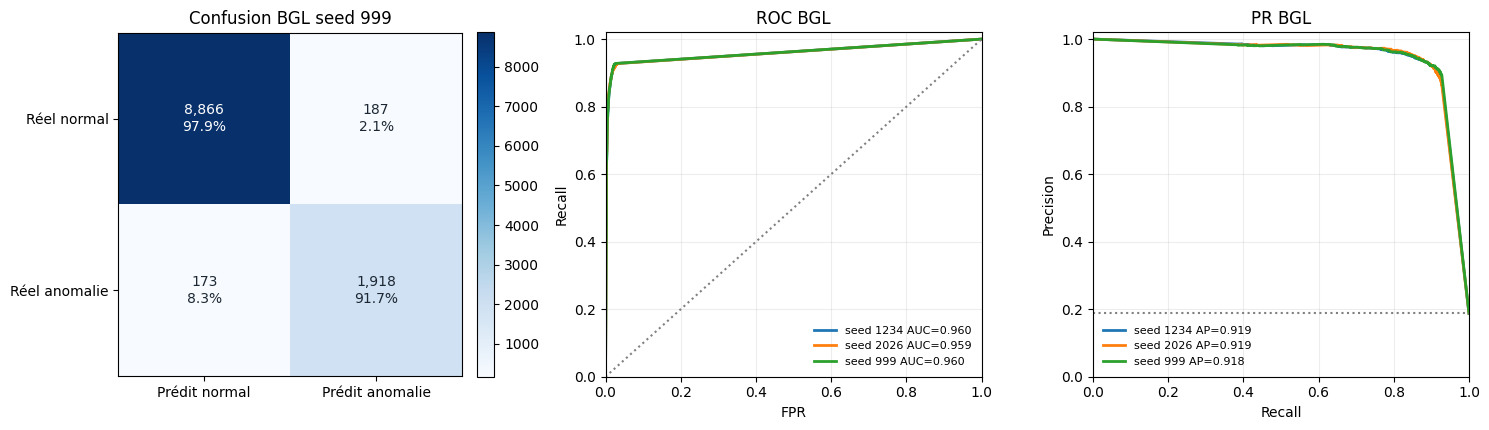

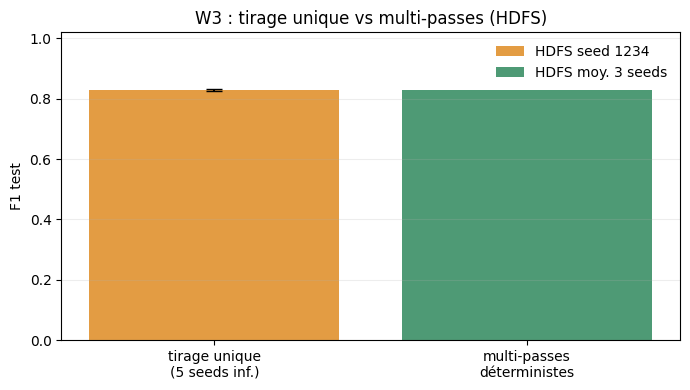

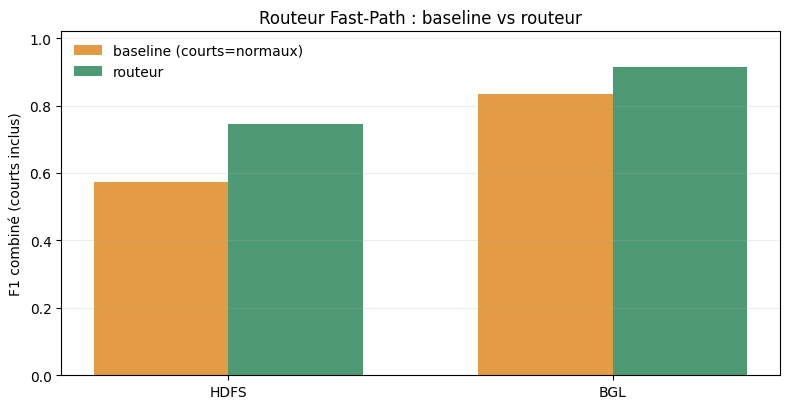

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc
for _ds in ["hdfs", "bgl"]:
    _rows = [V4_TEST[(_ds, _s)] for _s in V4_SEEDS if (_ds, _s) in V4_TEST]
    if not _rows:
        continue
    _best = max(_rows, key=lambda r: r["F1"])
    _sc = V4_SCORES[(_ds, _best["seed"])]["scores"]
    _yt = V4_SCORES[(_ds, _best["seed"])]["y"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    _cm = confusion_matrix(_yt, (_sc > _best["r"]).astype(int), labels=[0, 1])
    _rp = _cm / np.maximum(_cm.sum(axis=1, keepdims=True), 1)
    _im = axes[0].imshow(_cm, cmap="Blues")
    for _i in range(2):
        for _j in range(2):
            axes[0].text(_j, _i, f"{_cm[_i,_j]:,}\n{_rp[_i,_j]:.1%}", ha="center", va="center", fontsize=10,
                         color="white" if _cm[_i, _j] > _cm.max() * .55 else "#1d2733")
    axes[0].set_xticks([0, 1], ["Prédit normal", "Prédit anomalie"])
    axes[0].set_yticks([0, 1], ["Réel normal", "Réel anomalie"])
    axes[0].set_title(f"Confusion {_ds.upper()} seed {_best['seed']}")
    fig.colorbar(_im, ax=axes[0], fraction=.046, pad=.04)
    for _s in V4_SEEDS:
        if (_ds, _s) not in V4_SCORES:
            continue
        _ss = V4_SCORES[(_ds, _s)]["scores"]
        _f, _t, _ = roc_curve(_yt, _ss)
        axes[1].plot(_f, _t, linewidth=2, label=f"seed {_s} AUC={auc(_f,_t):.3f}")
    axes[1].plot([0, 1], [0, 1], color="grey", linestyle=":")
    axes[1].set(xlabel="FPR", ylabel="Recall", title=f"ROC {_ds.upper()}", xlim=(0, 1), ylim=(0, 1.02))
    axes[1].legend(frameon=False, fontsize=8); axes[1].grid(alpha=.22)
    for _s in V4_SEEDS:
        if (_ds, _s) not in V4_SCORES:
            continue
        _ss = V4_SCORES[(_ds, _s)]["scores"]
        _pp, _rr, _ = precision_recall_curve(_yt, _ss)
        axes[2].plot(_rr, _pp, linewidth=2, label=f"seed {_s} AP={average_precision_score(_yt,_ss):.3f}")
    axes[2].axhline(float(_yt.mean()), color="grey", linestyle=":")
    axes[2].set(xlabel="Recall", ylabel="Precision", title=f"PR {_ds.upper()}", xlim=(0, 1), ylim=(0, 1.02))
    axes[2].legend(frameon=False, fontsize=8); axes[2].grid(alpha=.22)
    fig.tight_layout(); fig.savefig(WORK_DIR / f"v4_diag_{_ds}.png", dpi=200, bbox_inches="tight"); plt.show()
if V4_MP.get("single_pass_spread"):
    fig, ax = plt.subplots(figsize=(7, 4))
    _sp = V4_MP["single_pass_spread"]
    ax.bar(["tirage unique\n(5 seeds inf.)"], [float(np.mean(_sp))], yerr=[float(np.std(_sp, ddof=1))],
           capsize=6, color="#E39C43", label="HDFS seed 1234")
    _mpf1 = np.mean([V4_MP[("hdfs", _s)]["F1"] for _s in V4_SEEDS if ("hdfs", _s) in V4_MP])
    ax.bar(["multi-passes\ndéterministes"], [_mpf1], color="#4E9A75", label="HDFS moy. 3 seeds")
    ax.set_ylim(0, 1.02); ax.set_ylabel("F1 test"); ax.set_title("W3 : tirage unique vs multi-passes (HDFS)")
    ax.legend(frameon=False); ax.grid(axis="y", alpha=.22)
    fig.tight_layout(); fig.savefig(WORK_DIR / "v4_multipass.png", dpi=200, bbox_inches="tight"); plt.show()
if V4_ROUTER:
    fig, ax = plt.subplots(figsize=(8, 4.2))
    _labs, _b, _r = [], [], []
    for (_ds, _k), _v in V4_ROUTER.items():
        if _k != "combined":
            continue
        _labs.append(_ds.upper()); _b.append(_v["base_F1"]); _r.append(_v["router_F1"])
    _x = np.arange(len(_labs)); _w = .35
    ax.bar(_x - _w / 2, _b, _w, label="baseline (courts=normaux)", color="#E39C43")
    ax.bar(_x + _w / 2, _r, _w, label="routeur", color="#4E9A75")
    ax.set_xticks(_x, _labs); ax.set_ylim(0, 1.02); ax.set_ylabel("F1 combiné (courts inclus)")
    ax.set_title("Routeur Fast-Path : baseline vs routeur"); ax.legend(frameon=False); ax.grid(axis="y", alpha=.22)
    fig.tight_layout(); fig.savefig(WORK_DIR / "v4_router.png", dpi=200, bbox_inches="tight"); plt.show()


## 13. Bundles d'inférence HDFS + BGL (I3 : exemples de paramètres par template)


In [15]:
V4_TPL = {}
for _ds, _struct, _outdir in [("hdfs", STRUCTURED_HDFS, OUTPUT_HDFS), ("bgl", STRUCTURED_BGL, OUTPUT_BGL)]:
    if (_ds, V4_SEEDS[0]) not in V4_TEST:
        continue
    _df = pd.read_csv(_struct, usecols=lambda c: c in ["EventId", "EventTemplate", "Content"], nrows=400000)
    _ids = dict(zip(_df.EventId.astype(str), _df.EventTemplate.astype(str))) if "EventTemplate" in _df else {}
    _ex = {}
    if "EventTemplate" in _df and "Content" in _df:
        _tmp = _df.drop_duplicates("EventId").set_index(_df.drop_duplicates("EventId").EventId.astype(str))["Content"].to_dict()
        _ex = {str(k): str(v)[:160] for k, v in _tmp.items()}
    V4_TPL[_ds] = _ids
    _best = max([V4_TEST[(_ds, _s)] for _s in V4_SEEDS if (_ds, _s) in V4_TEST], key=lambda r: r["F1"])
    _art = Path(f"/kaggle/working/logbert_v4_{_ds}_best")
    if _art.exists():
        shutil.rmtree(_art)
    _art.mkdir(parents=True, exist_ok=True)
    _, _opts = v4_train(_ds, int(_best["seed"]), float(_best["m"]))
    shutil.copy2(Path(_opts["model_path"]), _art / "best_bert.pth")
    shutil.copy2(Path(_opts["vocab_path"]), _art / "vocab.pkl")
    _manifest = {"model": f"Official LogBERT {_ds.upper()} (V4)", "repository_commit": REPO_COMMIT,
                 "dataset": _ds, "mask_ratio_m": float(_best["m"]), "top_g": int(_best["g"]),
                 "sequence_threshold_r": float(_best["r"]), "sequence_length": int(_opts["seq_len"]),
                 "minimum_sequence_length": int(_opts["min_len"]),
                 "id_to_template": _ids, "template_example_content": _ex,
                 "test_metrics": {k: _best[k] for k in ["Precision", "Recall", "F1", "FPR", "ROC_AUC", "PR_AUC", "seed"]}}
    (_art / "manifest.json").write_text(json.dumps(_manifest, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    print(_ds, "bundle :", _art, "| templates :", len(_ids), "| exemples :", len(_ex))
(WORK_DIR / "v4_templates.json").write_text(json.dumps({k: len(v) for k, v in V4_TPL.items()}, indent=2))
print("Bundles exportés.")


hdfs seed=1234 m=0.75 : reprise.
hdfs bundle : /kaggle/working/logbert_v4_hdfs_best | templates : 31 | exemples : 31
bgl seed=999 m=0.50 : reprise.
bgl bundle : /kaggle/working/logbert_v4_bgl_best | templates : 186 | exemples : 186
Bundles exportés.


## 14. Résultat unique + tableau FinOps 2 colonnes (C1)

Un seul JSON. FinOps : mêmes hypothèses de cascade (sessions = lignes/20, taux signalé mesuré HDFS 1,70 %, dedup /17 Heaps, cache ×0.25), deux colonnes : Copartis seul (5,7 M/j) vs projection TFI (50 M/j). Projection explicite, pas une mesure.


In [16]:
def _meanstd(rows, metric):
    import numpy as _np
    v = _np.array([r[metric] for r in rows], dtype=float)
    return {"mean": float(v.mean()), "std": float(v.std(ddof=1)) if len(v) > 2 else 0.0}
V4_FINAL = {"repo_commit": REPO_COMMIT, "seeds": V4_SEEDS, "splits": json.loads((WORK_DIR / "v4_splits.json").read_text())}
for _ds in ["hdfs", "bgl"]:
    _rows = [V4_TEST[(_ds, _s)] for _s in V4_SEEDS if (_ds, _s) in V4_TEST]
    if not _rows:
        continue
    V4_FINAL[_ds] = {"rows": _rows,
                     "agg": {m: _meanstd(_rows, m) for m in ["Precision", "Recall", "F1", "FPR", "ROC_AUC", "PR_AUC"]}}
V4_FINAL["multipass"] = {str(k): v for k, v in V4_MP.items()}
V4_FINAL["router"] = {str(k): v for k, v in V4_ROUTER.items()}
V4_FINAL["slm_timings_s"] = V4_SLM.get("timings", [])
(WORK_DIR / "v4_results.json").write_text(json.dumps(V4_FINAL, indent=2, default=str), encoding="utf-8")
print("v4_results.json sauvé.")
for _lines_day, _tag in [(5_700_000, "Copartis seul"), (50_000_000, "Projection TFI")]:
    _sess = _lines_day / 20
    _flag = _sess * 0.0170
    _calls = _flag / 17 * 0.25
    print(f"{_tag} ({_lines_day/1e6:.1f} M/j) : sessions={_sess:,.0f} -> signalées={_flag:,.0f} -> appels SLM={_calls:,.0f}/j "
          f"-> GPU={_calls*34.4/3600:.1f} h/j (à 34,4 s/appel, à re-mesurer W2.3)".replace(",", " "))


v4_results.json sauvé.
Copartis seul (5.7 M/j) : sessions=285 000 -> signalées=4 845 -> appels SLM=71/j -> GPU=0.7 h/j (à 34 4 s/appel  à re-mesurer W2.3)
Projection TFI (50.0 M/j) : sessions=2 500 000 -> signalées=42 500 -> appels SLM=625/j -> GPU=6.0 h/j (à 34 4 s/appel  à re-mesurer W2.3)
